# 02 — Exploratory Data Analysis

EDA aktual dari data processed. Semua grafik disimpan ke `artifacts/figures/` dan tabel ke `artifacts/tables/`.

In [1]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from discourse.eda import run_eda

df = pd.read_parquet(ROOT / "data/processed/all_splits.parquet")
print(df.shape)
print(df.columns.tolist())

(28448, 24)
['text_id', 'source_ids', 'text_raw', 'votes_tox', 'votes_pol', 'annotators_id', 'topic', 'initial_paragraph', 'n_tox', 'q_tox', 'hard_tox', 'mask_tox', 'entropy_tox', 'multi_tox', 'n_pol', 'q_pol', 'hard_pol', 'mask_pol', 'entropy_pol', 'multi_pol', 'group_id', 'split', 'text_proc', 'pipeline']


In [2]:
summary = run_eda(
    df,
    fig_dir=ROOT / "artifacts/figures",
    table_dir=ROOT / "artifacts/tables",
)
print(summary)

print("\nFigures:")
for p in sorted((ROOT / "artifacts/figures").glob("G*.png")):
    print(" -", p.name)

print("\nTables:")
for p in sorted((ROOT / "artifacts/tables").glob("G*.csv")):
    print(" -", p.name)

{'G01': [{'subset': 'tox_only', 'count': 0}, {'subset': 'pol_only', 'count': 0}, {'subset': 'both', 'count': 28448}, {'subset': 'either', 'count': 28448}], 'n_rows': 28448}

Figures:
 - G01_target_availability.png
 - G02_majority_labels.png
 - G03_joint_labels.png
 - G04_annotator_counts.png
 - G05_soft_polarization.png
 - G05_soft_toxicity.png
 - G06_entropy_polarization.png
 - G06_entropy_toxicity.png
 - G07_text_length.png
 - G09_surface_features.png
 - G10_split_sizes.png

Tables:
 - G01_target_availability.csv
 - G02_majority_labels.csv
 - G03_joint_labels.csv
 - G04_annotator_counts.csv
 - G05_soft_summary.csv
 - G06_entropy_by_n.csv
 - G07_text_length.csv
 - G09_surface_features.csv
 - G10_split_audit.csv


G01_target_availability.png


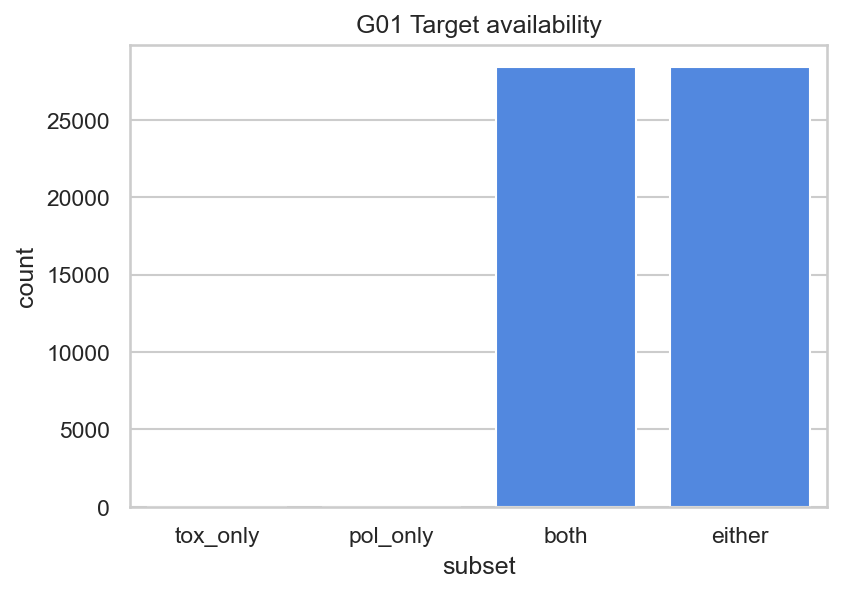

G02_majority_labels.png


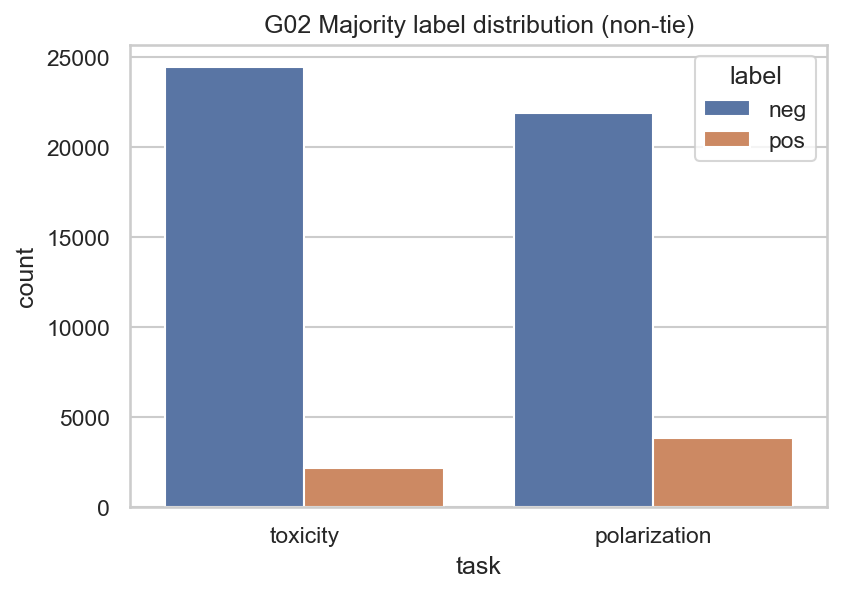

G03_joint_labels.png


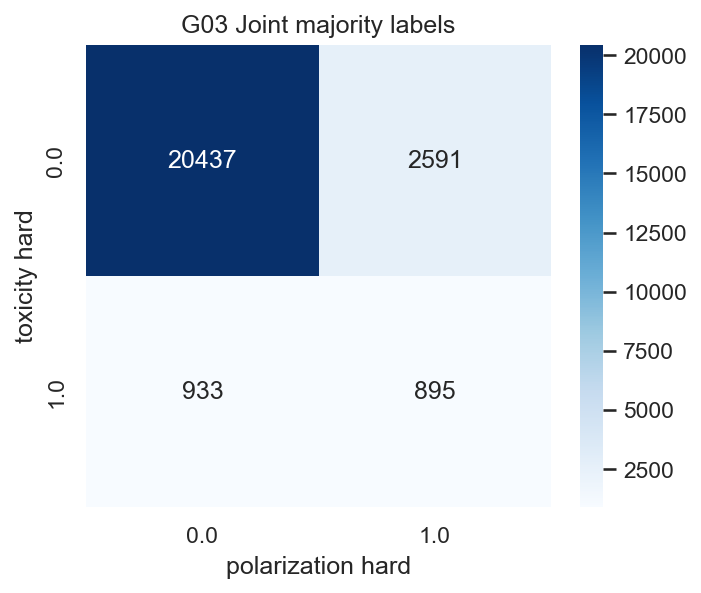

G04_annotator_counts.png


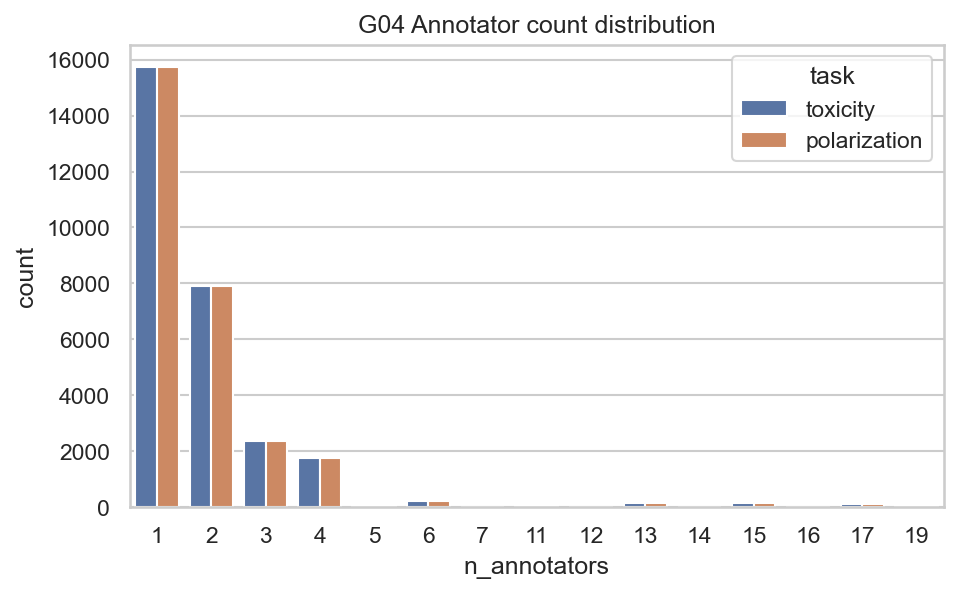

G07_text_length.png


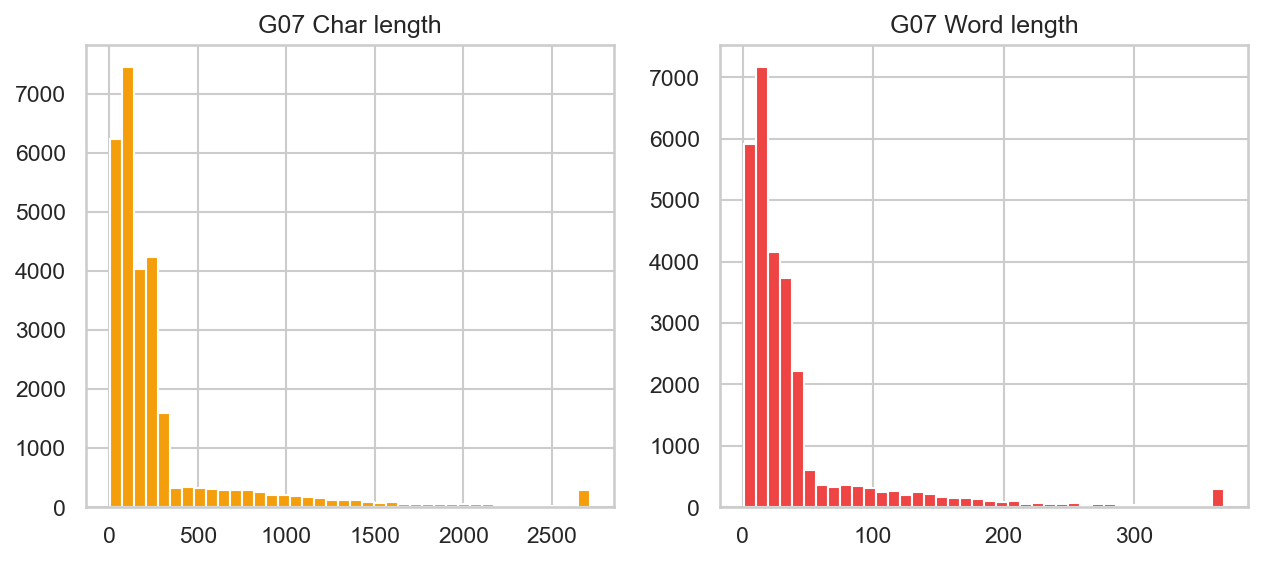

G10_split_sizes.png


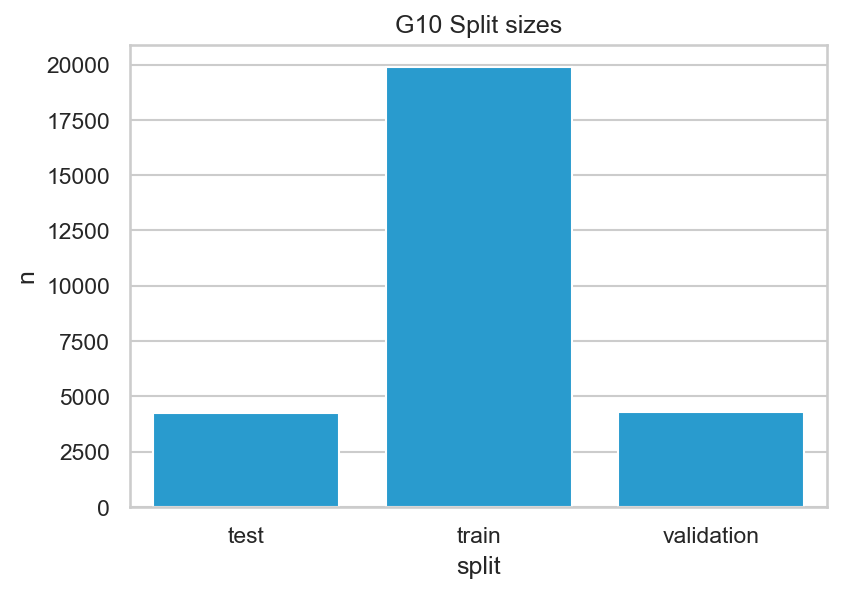

In [3]:
from IPython.display import Image, display

for name in [
    "G01_target_availability.png",
    "G02_majority_labels.png",
    "G03_joint_labels.png",
    "G04_annotator_counts.png",
    "G07_text_length.png",
    "G10_split_sizes.png",
]:
    path = ROOT / "artifacts/figures" / name
    if path.exists():
        print(name)
        display(Image(filename=str(path)))